# BERT: Bidirectional Encoders (Devlin et al., 2019)

GPT reads left to right because it is trained to predict the next token. That
works for generation, but it is a handicap for **understanding**. The meaning of
a word often depends on what comes after it: in *"the bank of the river"*, the
disambiguating word is two positions to the right.

BERT, *Pre-training of Deep Bidirectional Transformers for Language
Understanding*, keeps the Transformer **encoder**, lets every token see every
other token, and replaces next-token prediction with a different training game:
hide some tokens and recover them from both sides.

1. Why you cannot simply train a bidirectional language model
2. Masked language modelling and the 80/10/10 rule, simulated
3. A task only a bidirectional model can solve, trained both ways
4. Inputs: [CLS], [SEP], and three embeddings added together
5. BERT-base and BERT-large, counted to 110M and 340M
6. Fine-tuning, next-sentence prediction, and what came after

For the same encoder applied to brain signals instead of text, see
[BERT on EEG](/how-models-work/bert-on-eeg/).

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from hmw_motion import Scene, mix

torch.manual_seed(0); np.random.seed(0)
torch.set_num_threads(4)


def banner(title):
    print("=" * 78); print(f"  {title}"); print("=" * 78)


def step(label):
    print(); print(label); print("-" * 78)


def check(label, ok):
    print(f"  [{'PASS' if ok else 'FAIL'}] {label}")
    return ok


print("helpers ready")

helpers ready


## 1. Why not a bidirectional language model?

A left-to-right model predicts token $i$ from tokens $< i$. A right-to-left model
predicts it from tokens $> i$. ELMo trained one of each and concatenated their
features, which is *shallow* bidirectionality: the two directions never meet
inside the network.

Making a single deep network bidirectional breaks the objective. If every layer
sees every position, then by layer 2 the representation at position $i$ already
contains token $i$ itself, gathered through its neighbours. The model would
"predict" each word by copying it.

BERT's answer is to **remove the token from the input** and then predict it.
The paper calls this the *masked LM*, after the 1953 Cloze test.

## 2. Masked LM and the 80/10/10 rule

Choose 15% of token positions at random. For each chosen position:

* 80% of the time, replace the token with `[MASK]`
* 10% of the time, replace it with a random token
* 10% of the time, leave it unchanged

The loss is computed only at the chosen positions. The mixing is there because
`[MASK]` never appears at fine-tuning time. If the model only ever saw `[MASK]`
at predicted positions, it could learn that ordinary tokens need no thought.
The random and unchanged cases force it to keep a good representation of every
input token, since any one of them might be a target.

In [2]:
banner("SIMULATING THE MASKING RULE ON 2 MILLION TOKENS")
rng = np.random.default_rng(0)
V, N = 30522, 2_000_000
MASK = 103                                     # [MASK] id in BERT's vocabulary
tokens = rng.integers(1000, V, N)
chosen = rng.random(N) < 0.15
r = rng.random(N)
inp = tokens.copy()
to_mask = chosen & (r < 0.8)
to_rand = chosen & (r >= 0.8) & (r < 0.9)
inp[to_mask] = MASK
inp[to_rand] = rng.integers(1000, V, to_rand.sum())
keep = chosen & (r >= 0.9)

step("Fractions of ALL tokens")
for name, arr, theory in [("chosen as targets", chosen, 0.15), ("became [MASK]", to_mask, 0.12),
                          ("became a random token", to_rand, 0.015), ("chosen but unchanged", keep, 0.015)]:
    print(f"  {name:<24} {arr.mean():.4f}   (theory {theory})")
step("What the model sees at a target position")
print(f"  P(input is [MASK]            | target) = {(inp[chosen] == MASK).mean():.4f}")
print(f"  P(input equals the answer    | target) = {(inp[chosen] == tokens[chosen]).mean():.4f}")
print(f"  P(input is some other token  | target) = {((inp[chosen] != MASK) & (inp[chosen] != tokens[chosen])).mean():.4f}")
check("12% / 1.5% / 1.5% of all tokens, within 0.1%",
      abs(to_mask.mean() - .12) < 1e-3 and abs(to_rand.mean() - .015) < 1e-3 and abs(keep.mean() - .015) < 1e-3)

  SIMULATING THE MASKING RULE ON 2 MILLION TOKENS

Fractions of ALL tokens
------------------------------------------------------------------------------
  chosen as targets        0.1497   (theory 0.15)
  became [MASK]            0.1199   (theory 0.12)
  became a random token    0.0148   (theory 0.015)
  chosen but unchanged     0.0150   (theory 0.015)

What the model sees at a target position
------------------------------------------------------------------------------
  P(input is [MASK]            | target) = 0.8010
  P(input equals the answer    | target) = 0.1004
  P(input is some other token  | target) = 0.0987
  [PASS] 12% / 1.5% / 1.5% of all tokens, within 0.1%


In [3]:
def mask_scene():
    words = ["my", "dog", "is", "hairy", "and", "it", "loves", "to", "run", "in", "the", "park"]
    picks = {3: ("[MASK]", "amber", "80%: [MASK]"), 6: ("apple", "pink", "10%: random"),
             9: ("in", "green", "10%: unchanged")}
    sc = Scene(720, 330, dur=9.0, caption="BERT's masking: 15% of positions become targets, then 80/10/10",
               poster=7.5)
    xs, w_ = [], []
    x = 24
    for wd in words:
        w = 18 + 9.5 * len(wd)
        xs.append(x); w_.append(w); x += w + 8
    boxes, labels = [], []
    for i, wd in enumerate(words):
        boxes.append(sc.rect(xs[i], 90, w_[i], 40, fill="panel", stroke="grid", sw=1.5, rx=7))
        labels.append(sc.text(xs[i] + w_[i] / 2, 110, wd, size=15, mono=True))
    sc.text(360, 50, "input sentence", size=13, fill="muted")
    for k, (i, (rep, col, why)) in enumerate(picks.items()):
        t0 = 1.0 + 0.4 * k
        boxes[i].to(t0, t0 + 0.4, stroke="white", sw=3)
        tag = sc.text(xs[i] + w_[i] / 2, 156, "target", size=11, fill="white", opacity=0)
        tag.fade_in(t0, 0.3)
        t1 = 3.0 + 1.2 * k
        boxes[i].to(t1, t1 + 0.5, fill=mix("panel", col, 0.45), stroke=col)
        labels[i].to(t1, t1 + 0.2, opacity=0)
        labels[i].set(t1 + 0.2, s=rep)
        labels[i].to(t1 + 0.2, t1 + 0.5, opacity=1, fill="white")
        tag.to(t1, t1 + 0.4, opacity=0)
        lab = sc.text(xs[i] + w_[i] / 2, 160, why, size=12, fill=col, weight=700, opacity=0)
        lab.to(t1 + 0.2, t1 + 0.6, opacity=1, y=166, ease="out")
        ans = sc.text(xs[i] + w_[i] / 2, 236, f"predict: {words[i]}", size=12, fill="text", mono=True, opacity=0)
        ans.to(6.6, 7.2, opacity=1, y=226, ease="out")
        sc.arrow(xs[i] + w_[i] / 2, 186, xs[i] + w_[i] / 2, 208, stroke=col, sw=2, head=7, opacity=0).fade_in(6.6)
    sc.text(360, 290, "loss is computed only at the three target positions; the other nine are context",
            size=12, fill="muted", opacity=0).fade_in(7.4)
    sc.beat(0.0, "Pick 15% of positions as prediction targets (here 3 of 12).")
    sc.beat(3.0, "Most targets are replaced by [MASK]...")
    sc.beat(4.2, "...some by a random word, so the model cannot trust any input token blindly...")
    sc.beat(5.4, "...and some are left alone, so real words at a target position are not a giveaway.")
    sc.beat(6.6, "In every case the model must output the original word.")
    return sc

mask_scene()

<motion scene: BERT's masking: 15% of positions become targets, then 80/10/10 (38 elements, 9s)>

## 3. A task only a bidirectional model can solve

To see what bidirectionality buys, here is a task built so the answer **depends
on both sides**. Sequences of 12 digits. Even positions are random. Each odd
position holds the sum of its two neighbours, mod 10:

$$x_{2j+1} = (x_{2j} + x_{2j+2}) \bmod 10$$

Two models with the same architecture and size:

* **BERT-style**: no attention mask; a random odd position is replaced by
  `[MASK]` and predicted.
* **GPT-style**: causal mask, predict each token from the ones before it.

At an odd position, the left-to-right model has seen $x_{2j}$ but not
$x_{2j+2}$, and $x_{2j+2}$ is a uniformly random digit. So it **cannot** do
better than 10%, however long it trains. The bidirectional model has everything
it needs.

  SAME TRANSFORMER, TWO ATTENTION PATTERNS
  BERT-style (bidirectional)   accuracy at the sum positions after 1,500 steps: 1.000
  GPT-style (causal)           accuracy at the sum positions after 1,500 steps: 0.101
  chance                       0.100
  [PASS] the bidirectional model solves it (> 95%)
  [PASS] the causal model is stuck near chance (< 15%), as the argument predicts


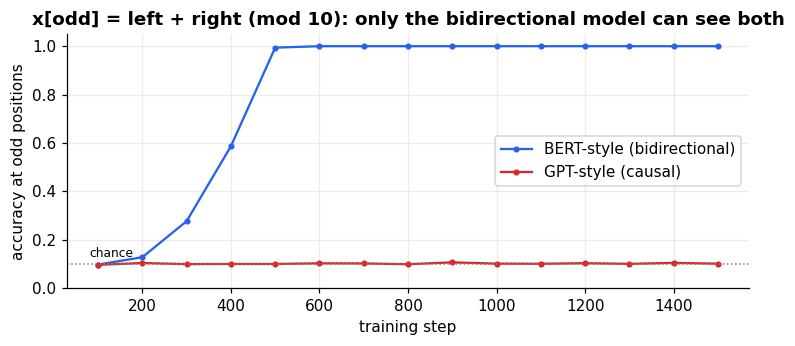

In [4]:
banner("SAME TRANSFORMER, TWO ATTENTION PATTERNS")
L_SEQ, MASK_ID, VOCAB = 13, 10, 11


def make_batch(n, g):
    x = torch.randint(0, 10, (n, L_SEQ), generator=g)
    for i in range(1, L_SEQ - 1, 2):
        x[:, i] = (x[:, i - 1] + x[:, i + 1]) % 10
    return x


class Encoder(nn.Module):
    def __init__(self, causal, d=64, h=4, L=2):
        super().__init__()
        self.causal = causal
        self.tok, self.pos = nn.Embedding(VOCAB, d), nn.Embedding(L_SEQ, d)
        layer = nn.TransformerEncoderLayer(d, h, 4 * d, dropout=0.0, batch_first=True)
        self.enc = nn.TransformerEncoder(layer, L)
        self.out = nn.Linear(d, 10)

    def forward(self, x):
        hdn = self.tok(x) + self.pos(torch.arange(x.shape[1]))
        m = nn.Transformer.generate_square_subsequent_mask(x.shape[1]) if self.causal else None
        return self.out(self.enc(hdn, mask=m, is_causal=self.causal))


g = torch.Generator().manual_seed(0)
odd = torch.arange(1, L_SEQ - 1, 2)
models = {"BERT-style (bidirectional)": Encoder(False), "GPT-style (causal)": Encoder(True)}
curves = {k: [] for k in models}
for name, m in models.items():
    opt = torch.optim.Adam(m.parameters(), lr=2e-3)
    for it in range(1, 1501):
        x = make_batch(256, g)
        if m.causal:                                  # predict x[i] from x[<i]
            logits = m(x[:, :-1])
            loss = F.cross_entropy(logits[:, odd - 1].reshape(-1, 10), x[:, odd].reshape(-1))
        else:                                         # mask one odd position, predict it
            pos = odd[torch.randint(0, len(odd), (x.shape[0],), generator=g)]
            xin = x.clone(); xin[torch.arange(x.shape[0]), pos] = MASK_ID
            logits = m(xin)[torch.arange(x.shape[0]), pos]
            loss = F.cross_entropy(logits, x[torch.arange(x.shape[0]), pos])
        opt.zero_grad(); loss.backward(); opt.step()
        if it % 100 == 0:
            with torch.no_grad():
                xt = make_batch(2000, g)
                if m.causal:
                    acc = (m(xt[:, :-1])[:, odd - 1].argmax(-1) == xt[:, odd]).float().mean().item()
                else:
                    pos = odd[torch.randint(0, len(odd), (2000,), generator=g)]
                    xin = xt.clone(); xin[torch.arange(2000), pos] = MASK_ID
                    acc = (m(xin)[torch.arange(2000), pos].argmax(-1) == xt[torch.arange(2000), pos]).float().mean().item()
            curves[name].append((it, acc))
    print(f"  {name:<28} accuracy at the sum positions after 1,500 steps: {curves[name][-1][1]:.3f}")
print(f"  {'chance':<28} 0.100")
bert_acc = curves["BERT-style (bidirectional)"][-1][1]
gpt_acc = curves["GPT-style (causal)"][-1][1]
check("the bidirectional model solves it (> 95%)", bert_acc > 0.95)
check("the causal model is stuck near chance (< 15%), as the argument predicts", gpt_acc < 0.15)

fig, ax = plt.subplots(figsize=(8, 3))
for (name, cv), col in zip(curves.items(), ["#2563eb", "#dc2626"]):
    c = np.array(cv); ax.plot(c[:, 0], c[:, 1], "o-", ms=3, label=name, color=col)
ax.axhline(0.1, color="gray", ls=":", lw=1); ax.text(80, 0.13, "chance", fontsize=8)
ax.set_ylim(0, 1.05); ax.set_xlabel("training step"); ax.set_ylabel("accuracy at odd positions")
ax.set_title("x[odd] = left + right (mod 10): only the bidirectional model can see both")
ax.legend()

In [5]:
def direction_scene():
    digits = [3, 9, 6, "?", 2, 7, 5]
    sc = Scene(720, 340, dur=8.0, caption="What each model can see when predicting the hidden digit",
               poster=7.0)
    xs = [140 + i * 70 for i in range(len(digits))]
    for row, (y, name, col, acc) in enumerate([(100, "BERT-style", "cyan", bert_acc),
                                              (240, "GPT-style", "pink", gpt_acc)]):
        sc.text(20, y - 50, name, size=15, fill=col, anchor="start", weight=700)
        for i, dg in enumerate(digits):
            hidden = dg == "?"
            sc.rect(xs[i] - 24, y - 22, 48, 44, fill=mix("panel", "amber", 0.4) if hidden else "panel",
                    stroke="amber" if hidden else "grid", sw=2 if hidden else 1.5, rx=8)
            sc.text(xs[i], y, "[M]" if hidden else str(dg), size=17 if not hidden else 13, mono=True,
                    fill="amber" if hidden else "text")
        tgt = xs[3]
        for i in range(len(digits)):
            if i == 3:
                continue
            visible = row == 0 or i < 3
            if not visible:
                sc.rect(xs[i] - 26, y - 24, 52, 48, fill="bg", rx=8, opacity=0).to(1.0, 1.6, opacity=0.78)
                continue
            src_y = y - 26
            hgt = 14 + abs(xs[i] - tgt) * 0.16
            pts_end = []
            for u in np.linspace(0, 1, 20):
                pts_end += [(1 - u) ** 2 * xs[i] + 2 * u * (1 - u) * (xs[i] + tgt) / 2 + u * u * tgt,
                            (1 - u) ** 2 * src_y + 2 * u * (1 - u) * (src_y - 2 * hgt) + u * u * src_y]
            ln = sc.poly([xs[i], src_y] * 20, stroke=col, sw=2)
            ln.to(1.4 + 0.12 * i, 2.4 + 0.12 * i, pts=pts_end, ease="out")
        sc.num(690, y, 0, dec=1, post="%", size=22, fill=col, anchor="end", opacity=0).to(4.2, 5.4, v=acc * 100,
                                                                                         opacity=1)
        sc.text(690, y + 30, "test accuracy", size=11, fill="muted", anchor="end", opacity=0).fade_in(4.2)
    sc.text(xs[3], 300, "answer = (6 + 2) mod 10 = 8", size=13, fill="amber", mono=True, opacity=0).fade_in(3.0)
    sc.beat(0.0, "The hidden digit is the sum of its two neighbours, mod 10.")
    sc.beat(1.4, "Bidirectional attention reaches both neighbours; causal attention stops at the left one.")
    sc.beat(4.2, "Measured on the two models trained above: one solves it, the other is at chance.")
    return sc

direction_scene()

<motion scene: What each model can see when predicting the hidden digit (47 elements, 8s)>

## 4. Inputs: [CLS], [SEP] and three embeddings

BERT's input packs one or two text segments into a single sequence:

`[CLS]  my dog is cute  [SEP]  he likes play ##ing  [SEP]`

Each position's input vector is the **sum** of three learned embeddings:

$$\text{input}_i = E_{\text{token}}[x_i] + E_{\text{segment}}[A \text{ or } B] + E_{\text{position}}[i]$$

* **WordPiece tokens**, 30,522 of them (rare words split into pieces such as
  `play ##ing`)
* **Segment** A or B, telling the two sentences apart
* **Learned positions**, up to 512

The final hidden state of `[CLS]` is a summary of the whole sequence, used for
classification.

## 5. BERT-base and BERT-large, counted

The paper reports 110M parameters for BERT-base (L=12, H=768, A=12) and 340M
for BERT-large (L=24, H=1024, A=16). Counting every matrix, bias and layer norm:

In [6]:
banner("COUNTING BERT")
def bert_params(L, H, V=30522, P=512, S=2):
    emb = (V + P + S) * H + 2 * H                          # three tables + LayerNorm
    attn = 4 * H * H + 4 * H
    ff = 2 * H * 4 * H + 4 * H + H
    ln = 2 * 2 * H
    pooler = H * H + H                                     # dense layer on [CLS]
    return emb, L * (attn + ff + ln), pooler

for name, L, H, rep in [("BERT-base", 12, 768, 110e6), ("BERT-large", 24, 1024, 340e6)]:
    emb, layers, pool = bert_params(L, H)
    tot = emb + layers + pool
    print(f"  {name:<10} embeddings {emb/1e6:5.1f}M + {L} layers {layers/1e6:6.1f}M + pooler {pool/1e6:4.2f}M "
          f"= {tot/1e6:6.1f}M   (paper: {rep/1e6:.0f}M)")

step("Check the formula against a real PyTorch encoder of BERT-base shape")
layer = nn.TransformerEncoderLayer(768, 12, 3072, batch_first=True)
pt = sum(p.numel() for p in layer.parameters())
mine = 4 * 768 * 768 + 4 * 768 + 2 * 768 * 3072 + 3072 + 768 + 4 * 768
check(f"one layer: formula {mine:,} == PyTorch {pt:,}", mine == pt)

  COUNTING BERT
  BERT-base  embeddings  23.8M + 12 layers   85.1M + pooler 0.59M =  109.5M   (paper: 110M)
  BERT-large embeddings  31.8M + 24 layers  302.3M + pooler 1.05M =  335.1M   (paper: 340M)

Check the formula against a real PyTorch encoder of BERT-base shape
------------------------------------------------------------------------------
  [PASS] one layer: formula 7,087,872 == PyTorch 7,087,872


## 6. Fine-tuning, next-sentence prediction, and what came after

Fine-tuning is lightweight. For classification, put a linear layer on the
`[CLS]` state. For question answering (SQuAD), learn just two vectors, a start
vector $S$ and an end vector $E$. The probability that the answer starts at
token $i$ is $\text{softmax}_i(S \cdot T_i)$, where $T_i$ is the final hidden
state, and the end is predicted the same way. Everything else is the pre-trained
network.

The paper also trained a second objective, **next-sentence prediction**: given
segments A and B, is B the actual next sentence (50% of the time) or a random
one? The paper's ablation found it helped. RoBERTa (2019) later trained longer,
on more data, with dynamic masking and *without* NSP, and matched or beat BERT.
So NSP is the part of the recipe that did not last.

**Results.** BERT-large set new records on eleven tasks: a GLUE score of 80.5
(7.7 points above the previous best), MultiNLI accuracy of 86.7%, and SQuAD v1.1
F1 of 93.2.

## Summary

* A deep bidirectional language model would see the answer through its
  neighbours, so BERT hides 15% of tokens and predicts them: the masked LM.
* Of the chosen tokens, 80% become `[MASK]`, 10% a random token and 10% stay
  unchanged. The simulation reproduces 12%, 1.5% and 1.5% of all tokens.
* On a task where the answer depends on the right-hand context, the
  bidirectional model learns it and the causal model provably cannot.
* Inputs are token + segment + position embeddings, with `[CLS]` and `[SEP]`.
  The configurations count to 109.5M and 335M parameters, within 2% of the
  paper's 110M and 340M.
* The trade-off: an encoder like BERT understands but does not generate. That
  is why later work split into encoders for retrieval and classification and
  decoders (the GPT line) for generation.